# Exoplanet Classification: KNN and SVM
**DATA 245 · Machine Learning · Group Katham-Pak-Waseem-Yarrapragada-4**
**Venkata Sai Bhavana Yarrapragada (020046806): Distance & Margin-Based Models**

This notebook contains all of my work on K-Nearest Neighbors (KNN) and Support Vector Machines (SVM) for classifying NASA Kepler Objects of Interest as **Confirmed**, **Candidate**, or **False Positive**.

| Step | What it does |
|---|---|
| 1 | Understanding the data |
| 2 | Scaling experiment: no scaling vs StandardScaler vs MinMaxScaler |
| 3 | KNN: choosing k |
| 4 | KNN: full tuning (k, distance, weighting, scaler) |
| 5 | SVM tuning: Linear vs RBF, C, gamma, class balancing |
| 6 | Final comparison: default vs tuned, per-class scores, confusion matrices, ROC-AUC |
| 7 | Finalizing the SVM: larger C values and per-class thresholds |
| 10 | Bias-variance analysis |

Steps 8, 9 and 11 are done with the team: agreeing on the feature set, opening the test set, and comparing all models.

**Rules from the team's shared setup**
- Use the team's NASA table, 76-feature list and saved host-star splits. No new split.
- Use only the **development** partition. The test partition stays closed until the whole team agrees to open it.
- Cross-validation uses the saved `dev_fold` values (0–4), so planets from the same star are never in both training and validation.
- The imputer and scaler are fitted **inside each training fold** with a scikit-learn `Pipeline`.
- Every main experiment is run with **all 76 features** and **without the 20 centroid columns (56 features)**.
- The main metric is **macro-F1**, which treats all three classes equally.

**How to run:** this notebook lives in `experiments/person2_knn_svm/`. Run all cells; tables go to `results/person2/notebook/` and charts to `figures/person2/`. You need `pandas`, `numpy`, `scikit-learn`, `matplotlib` and `jupyter`. The full notebook takes roughly 20–40 minutes, mostly in the SVM grid searches (Steps 5 and 7).

## Setup

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the repository root (works from experiments/person2_knn_svm/ or the repo root)
ROOT = Path.cwd()
while not (ROOT / "src" / "exoplanet" / "evaluation.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from exoplanet.config import DATA_PROCESSED, RAW_CSV
from exoplanet.io import load_koi
from exoplanet.preprocess import primary_learning_frame

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import PredefinedSplit, cross_validate, GridSearchCV, validation_curve
from sklearn.metrics import (f1_score, accuracy_score, roc_auc_score, confusion_matrix,
                             precision_recall_fscore_support)

RESULTS = ROOT / "results" / "person2" / "notebook"
FIGURES = ROOT / "figures" / "person2"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
CLASSES = ["CONFIRMED", "CANDIDATE", "FALSE POSITIVE"]

# Chart style used throughout
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
def tidy(ax):
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)

print("Project folder:", ROOT)

Project folder: /home/claude/work


### Helper functions
`make_pipe` builds the imputer → scaler → model chain, which is refitted on the training folds every time. `cv_score` runs the 5-fold grouped cross-validation on the team's saved folds.

In [2]:
def make_pipe(model, scaler="standard"):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scaler == "standard": steps.append(("scale", StandardScaler()))
    elif scaler == "minmax": steps.append(("scale", MinMaxScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

def cv_score(pipe, cols, train_score=False):
    r = cross_validate(pipe, X[cols], y, cv=CV, n_jobs=-1, return_train_score=train_score,
                       scoring={"f1": "f1_macro", "acc": "accuracy"})
    out = {"macro_F1": r["test_f1"].mean(), "F1_std": r["test_f1"].std(), "accuracy": r["test_acc"].mean()}
    if train_score: out["train_macro_F1"] = r["train_f1"].mean()
    return out

## Step 1: Understanding the data
Before training anything, I checked what the models will work with: how many objects there are, how balanced the classes are, whether the folds are fair, and how differently the features are measured.

In [3]:
frame = load_koi(RAW_CSV).reset_index(drop=True)
splits = pd.read_csv(DATA_PROCESSED / "proposed_splits.csv")
features = pd.read_csv(DATA_PROCESSED / "proposed_leakage_aware_features.csv")

ALL_76 = features["column"].tolist()
CENTROID = features.loc[features["provisional"].astype(bool), "column"].tolist()
NO_CENTROID = [c for c in ALL_76 if c not in CENTROID]
FEATURE_SETS = {"All 76": ALL_76, "No centroid (56)": NO_CENTROID}

dev = (primary_learning_frame(frame, splits, ALL_76)
       .query("partition == 'development'").reset_index(drop=True))
assert (dev["dev_fold"] >= 0).all()            # no test rows

X = dev[ALL_76].apply(pd.to_numeric, errors="coerce")
y = dev["koi_disposition"].to_numpy()
folds = dev["dev_fold"].to_numpy()
CV = PredefinedSplit(folds)                   # the team's saved grouped folds

print(f"Development rows: {len(dev):,} KOIs from {dev['kepid'].nunique():,} stars")
print(f"Features: {len(ALL_76)} total, {len(CENTROID)} centroid, {len(NO_CENTROID)} without centroid")
stars_in_two_folds = (dev.groupby("kepid")["dev_fold"].nunique() > 1).sum()
print("Stars appearing in more than one fold:", stars_in_two_folds)

Development rows: 7,381 KOIs from 6,357 stars
Features: 76 total, 20 centroid, 56 without centroid
Stars appearing in more than one fold: 0


In [4]:
balance = pd.crosstab(dev["dev_fold"], dev["koi_disposition"], normalize="index")[CLASSES]
balance.loc["All folds"] = dev["koi_disposition"].value_counts(normalize=True)[CLASSES]
display((balance * 100).round(1).astype(str) + "%")

koi_disposition,CONFIRMED,CANDIDATE,FALSE POSITIVE
dev_fold,,,
0,29.6%,20.5%,49.9%
1,29.7%,20.4%,49.9%
2,29.6%,20.3%,50.1%
3,29.8%,20.6%,49.6%
4,30.1%,20.2%,49.8%
All folds,29.8%,20.4%,49.8%


About half of the objects are False Positives, and only about one in five are Candidates. A model could get roughly 50% accuracy by always guessing "False Positive", which is why I use **macro-F1** as my main metric. The class shares are nearly identical in every fold, so each fold is a fair test.

In [5]:
spread = X.std().sort_values()
display(pd.DataFrame({"standard deviation": pd.concat([spread.head(3), spread.tail(3)])}))
print(f"Largest / smallest spread: {spread.max() / spread.min():,.0f}x")

,standard deviation
koi_period_err1,0.008037
koi_jmag_err,0.010555
koi_hmag_err,0.013435
koi_insol_err2,75510.455785
koi_depth,80573.442783
koi_insol,121150.767318


Largest / smallest spread: 15,073,886x


The features are on wildly different scales. It's like comparing houses by price in dollars and number of bedrooms: without adjusting units, price decides everything. KNN and SVM both rely on distances, so I expect scaling to matter a lot. Step 2 tests this.

## Step 2: Scaling experiment
I trained all three models with default settings and changed only the scaling step:
- **None**: raw values
- **StandardScaler**: each feature shifted to mean 0 and standard deviation 1
- **MinMaxScaler**: each feature squeezed into the 0–1 range

In [6]:
models = {"KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
          "SVM RBF": lambda: SVC(kernel="rbf"),
          "SVM Linear": lambda: LinearSVC(max_iter=5000)}
rows = []
for fs, cols in FEATURE_SETS.items():
    for m, model in models.items():
        for s, scaler in [("None", None), ("StandardScaler", "standard"), ("MinMaxScaler", "minmax")]:
            rows.append({"features": fs, "model": m, "scaling": s, **cv_score(make_pipe(model(), scaler), cols)})
scaling = pd.DataFrame(rows)
scaling.to_csv(RESULTS / "scaling_experiment.csv", index=False)
display(scaling.pivot_table(index=["features", "model"], columns="scaling", values="macro_F1", sort=False)
        [["None", "StandardScaler", "MinMaxScaler"]].round(3))

scaling                       None  StandardScaler  MinMaxScaler
features         model                                          
All 76           KNN (k=5)   0.607           0.731         0.707
                 SVM RBF     0.263           0.778         0.673
                 SVM Linear  0.603           0.765         0.742
No centroid (56) KNN (k=5)   0.607           0.636         0.612
                 SVM RBF     0.263           0.663         0.515
                 SVM Linear  0.573           0.657         0.603

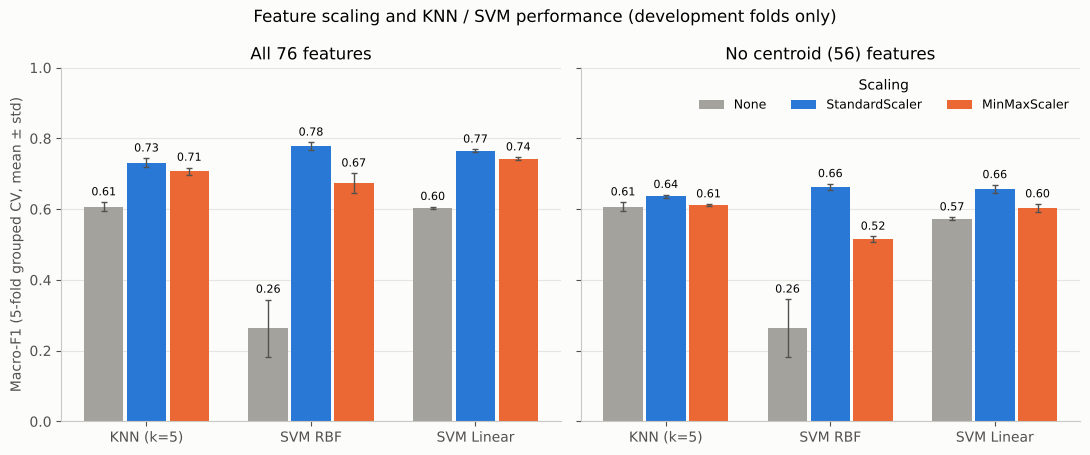

In [7]:
colors = {"None": GRAY, "StandardScaler": BLUE, "MinMaxScaler": ORANGE}
names = list(models)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    sub = scaling[scaling.features == fs]
    for i, (s, col) in enumerate(colors.items()):
        r = sub[sub.scaling == s].set_index("model").loc[names]
        b = ax.bar(np.arange(3) + (i - 1) * 0.26, r.macro_F1, 0.24, color=col, label=s,
                   yerr=r.F1_std, error_kw=dict(ecolor="#52514e", lw=1, capsize=2))
        ax.bar_label(b, fmt="%.2f", fontsize=8, padding=3)
    ax.set_xticks(range(3), names); ax.set_ylim(0, 1); ax.set_title(f"{fs} features"); tidy(ax)
axes[0].set_ylabel("Macro-F1 (5-fold grouped CV, mean ± std)")
axes[1].legend(title="Scaling", frameon=False, ncol=3, fontsize=9, loc="upper right")
fig.suptitle("Feature scaling and KNN / SVM performance (development folds only)")
fig.tight_layout(); fig.savefig(FIGURES / "step2_scaling_experiment.png", dpi=200); plt.show()

**What I found:**
- Scaling improved every model, and StandardScaler was the best choice in every case.
- The RBF SVM without scaling collapsed to about 0.26 macro-F1. It predicted almost everything as False Positive, so it was no better than always guessing the biggest class. After scaling it became the best model.
- MinMaxScaler did worse than StandardScaler because a few extreme outliers squash most values into a tiny part of the 0–1 range.
- Unscaled KNN scored the same with or without the centroid columns, because the huge-valued features drowned out the small ones.

**From here on, every model uses StandardScaler.**

## Step 3: KNN – choosing k
I tested every odd k from 1 to 51 and recorded the score on the training folds and on the validation folds (new stars).

In [8]:
krows = []
for fs, cols in FEATURE_SETS.items():
    for k in range(1, 52, 2):
        krows.append({"features": fs, "k": k, **cv_score(make_pipe(KNeighborsClassifier(n_neighbors=k)), cols, train_score=True)})
ksweep = pd.DataFrame(krows)
ksweep.to_csv(RESULTS / "knn_k_sweep.csv", index=False)
display(ksweep.loc[ksweep.groupby("features", sort=False)["macro_F1"].idxmax()].round(3))

,features,k,macro_F1,F1_std,accuracy,train_macro_F1
1,All 76,3,0.733,0.011,0.772,0.845
28,No centroid (56),5,0.636,0.005,0.696,0.751


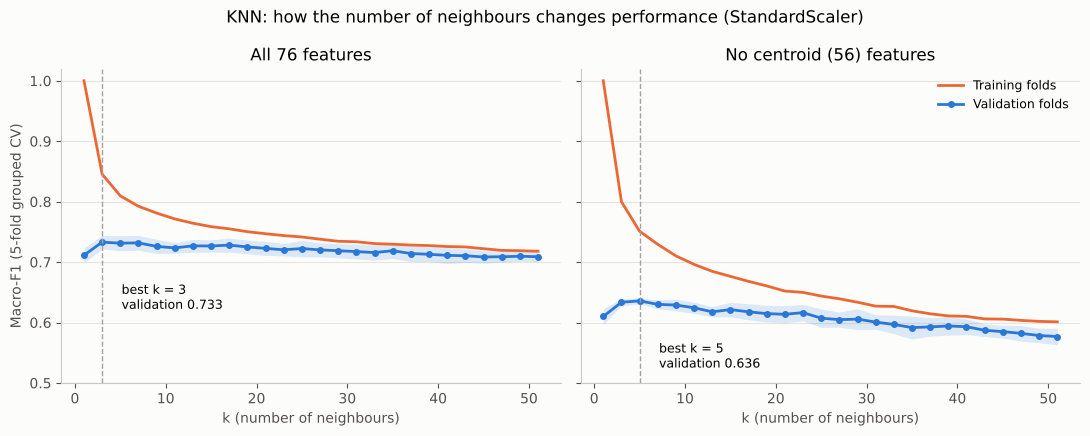

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (fs, s) in zip(axes, ksweep.groupby("features", sort=False)):
    ax.plot(s.k, s.train_macro_F1, "-", color=ORANGE, lw=2, label="Training folds")
    ax.plot(s.k, s.macro_F1, "-o", color=BLUE, lw=2, ms=4, label="Validation folds")
    ax.fill_between(s.k, s.macro_F1 - s.F1_std, s.macro_F1 + s.F1_std, color=BLUE, alpha=0.15, lw=0)
    b = s.loc[s.macro_F1.idxmax()]
    ax.axvline(b.k, color=GRAY, ls="--", lw=1)
    ax.annotate(f"best k = {int(b.k)}\nvalidation {b.macro_F1:.3f}", (b.k, b.macro_F1),
                xytext=(14, -48), textcoords="offset points", fontsize=9)
    ax.set_title(f"{fs} features"); ax.set_xlabel("k (number of neighbours)"); ax.set_ylim(0.5, 1.02); tidy(ax)
axes[0].set_ylabel("Macro-F1 (5-fold grouped CV)"); axes[1].legend(frameon=False, fontsize=9)
fig.suptitle("KNN: how the number of neighbours changes performance (StandardScaler)")
fig.tight_layout(); fig.savefig(FIGURES / "step3_knn_k_sweep.png", dpi=200); plt.show()

**What I found:**
- **k = 1 overfits.** It scores a perfect 1.00 on training, since each point's nearest neighbour is itself, but only about 0.71 on new stars.
- **Large k oversmooths.** Both scores slowly fall as the model averages over too many neighbours.
- **The best k is small (3–5),** but with all 76 features everything from k = 3 to about 25 is within normal fold-to-fold variation, so the curve is fairly flat.

## Step 4: KNN – full tuning
A grid search over 128 combinations for each feature set:
- `n_neighbors`: 3, 5, 7, 9, 11, 15, 21, 31
- `metric`: Euclidean (straight line) or Manhattan (sum of differences)
- `weights`: uniform (equal votes) or distance (closer neighbours count more)
- `scaler`: StandardScaler or MinMaxScaler

In [10]:
knn_grid = {"scale": [StandardScaler(), MinMaxScaler()],
            "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
            "model__metric": ["euclidean", "manhattan"],
            "model__weights": ["uniform", "distance"]}
out, knn_best = [], {}
for fs, cols in FEATURE_SETS.items():
    gs = GridSearchCV(make_pipe(KNeighborsClassifier()), knn_grid, cv=CV, n_jobs=-1, refit=False,
                      scoring={"f1": "f1_macro", "acc": "accuracy"})
    gs.fit(X[cols], y)
    r = pd.DataFrame(gs.cv_results_)
    out.append(pd.DataFrame({"features": fs, "scaler": r.param_scale.map(lambda s: type(s).__name__),
        "k": r.param_model__n_neighbors, "metric": r.param_model__metric, "weights": r.param_model__weights,
        "macro_F1": r.mean_test_f1, "F1_std": r.std_test_f1, "accuracy": r.mean_test_acc}))
knn_grid_df = pd.concat(out, ignore_index=True)
knn_grid_df.to_csv(RESULTS / "knn_grid_search.csv", index=False)
for fs, s in knn_grid_df.groupby("features", sort=False):
    b = s.loc[s.macro_F1.idxmax()]
    knn_best[fs] = dict(n_neighbors=int(b.k), metric=b.metric, weights=b.weights)
    print(f"{fs}: best macro-F1 {b.macro_F1:.3f} with {b.scaler}, k={int(b.k)}, {b.metric}, {b.weights}")

All 76: best macro-F1 0.736 with StandardScaler, k=7, euclidean, distance
No centroid (56): best macro-F1 0.636 with StandardScaler, k=5, euclidean, uniform


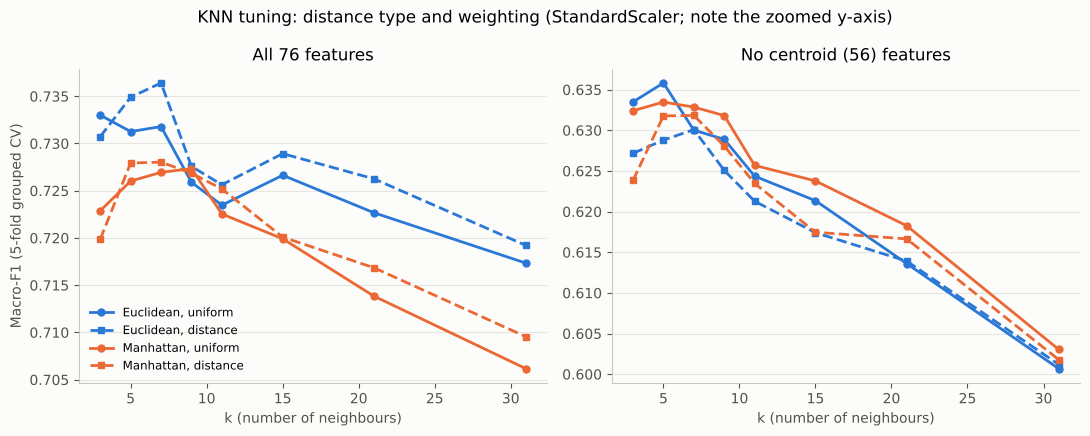

In [11]:
combos = [("euclidean", "uniform", BLUE, "-", "o"), ("euclidean", "distance", BLUE, "--", "s"),
          ("manhattan", "uniform", ORANGE, "-", "o"), ("manhattan", "distance", ORANGE, "--", "s")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (fs, s) in zip(axes, knn_grid_df.groupby("features", sort=False)):
    s = s[s.scaler == "StandardScaler"]
    for m, w, col, ls, mk in combos:
        t = s[(s.metric == m) & (s.weights == w)].sort_values("k")
        ax.plot(t.k, t.macro_F1, ls, color=col, marker=mk, ms=5, lw=2, label=f"{m.title()}, {w}")
    ax.set_title(f"{fs} features"); ax.set_xlabel("k (number of neighbours)"); tidy(ax)
axes[0].set_ylabel("Macro-F1 (5-fold grouped CV)"); axes[0].legend(frameon=False, fontsize=8.5, loc="lower left")
fig.suptitle("KNN tuning: distance type and weighting (StandardScaler; note the zoomed y-axis)")
fig.tight_layout(); fig.savefig(FIGURES / "step4_knn_tuning.png", dpi=200); plt.show()

**What I found:** tuning barely helps KNN. The best setting improves on the plain default (k = 5, scaled) by only about 0.005, less than the normal variation between folds. Euclidean distance and StandardScaler work best. For KNN, **scaling matters far more than tuning.**

## Step 5: SVM tuning
- **Linear SVM** draws straight boundaries. I tuned `C`.
- **RBF SVM** can draw curved boundaries. I tuned `C` (how much errors are penalized) and `gamma` (how local each point's influence is).
- Each setting was tried with and without `class_weight="balanced"`, which gives the smaller Candidate class more weight.

This is the slowest part of the notebook (about 500 model fits).

In [12]:
lin_grid = {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}
rbf_grid = {"model__C": [0.3, 1, 3, 10, 30], "model__gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
            "model__class_weight": [None, "balanced"]}
out = []
for fs, cols in FEATURE_SETS.items():
    for kern, model, grid in [("Linear", LinearSVC(max_iter=10000), lin_grid), ("RBF", SVC(kernel="rbf"), rbf_grid)]:
        t = time.time()
        gs = GridSearchCV(make_pipe(model), grid, cv=CV, n_jobs=-1, refit=False, return_train_score=True,
                          scoring={"f1": "f1_macro", "acc": "accuracy"}).fit(X[cols], y)
        r = pd.DataFrame(gs.cv_results_)
        out.append(pd.DataFrame({"features": fs, "kernel": kern, "C": r.param_model__C,
            "gamma": r["param_model__gamma"].astype(str) if "param_model__gamma" in r else "-",
            "class_weight": r.param_model__class_weight.map(lambda v: "balanced" if v == "balanced" else "none"),
            "macro_F1": r.mean_test_f1, "F1_std": r.std_test_f1, "accuracy": r.mean_test_acc,
            "train_macro_F1": r.mean_train_f1}))
        print(f"{fs} · {kern}: {time.time() - t:.0f}s")
svm_grid_df = pd.concat(out, ignore_index=True)
svm_grid_df.to_csv(RESULTS / "svm_grid_search.csv", index=False)
display(svm_grid_df.loc[svm_grid_df.groupby(["features", "kernel"], sort=False)["macro_F1"].idxmax()].round(3))

All 76 · Linear: 153s


All 76 · RBF: 433s


No centroid (56) · Linear: 57s


No centroid (56) · RBF: 414s


,features,kernel,C,gamma,class_weight,macro_F1,F1_std,accuracy,train_macro_F1
7,All 76,Linear,10.0,-,balanced,0.775,0.010,0.808,0.787
43,All 76,RBF,10.0,scale,balanced,0.789,0.010,0.816,0.883
65,No centroid (56),Linear,10.0,-,balanced,0.707,0.005,0.755,0.716
113,No centroid (56),RBF,30.0,0.01,balanced,0.732,0.006,0.757,0.813


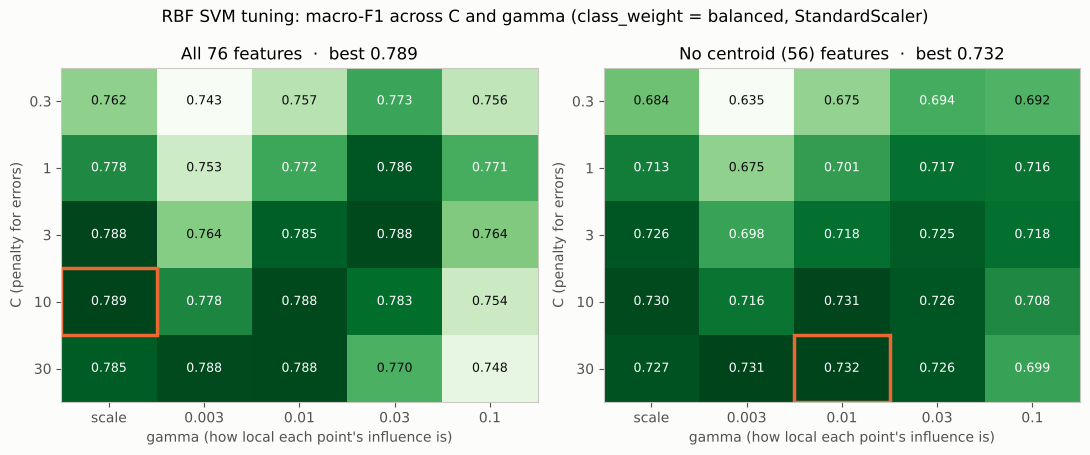

In [13]:
order = ["scale", "0.003", "0.01", "0.03", "0.1"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, fs in zip(axes, FEATURE_SETS):
    s = svm_grid_df[(svm_grid_df.features == fs) & (svm_grid_df.kernel == "RBF") & (svm_grid_df.class_weight == "balanced")]
    h = s.pivot_table(index="C", columns="gamma", values="macro_F1")[order]
    ax.imshow(h.values, cmap="Greens", aspect="auto")
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            v = h.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if v > h.values.min() + 0.6 * (h.values.max() - h.values.min()) else "#0b0b0b")
    r, c = np.unravel_index(h.values.argmax(), h.shape)
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=ORANGE, lw=2.5))
    ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(h)), [f"{v:g}" for v in h.index])
    ax.set_xlabel("gamma (how local each point's influence is)"); ax.set_ylabel("C (penalty for errors)")
    ax.set_title(f"{fs} features  ·  best {h.values.max():.3f}")
fig.suptitle("RBF SVM tuning: macro-F1 across C and gamma (class_weight = balanced, StandardScaler)")
fig.tight_layout(); fig.savefig(FIGURES / "step5_svm_rbf_heatmap.png", dpi=200); plt.show()

**What I found:**
- **RBF beats Linear** with both feature sets, so the boundary between the classes isn't a straight line.
- **Class balancing helps most without the centroid columns.** It lifts both SVMs by about 0.05 macro-F1, because the model stops ignoring the smaller Candidate class.
- **Best RBF settings:** C = 10, gamma = "scale" (all 76 features), and C = 30, gamma = 0.01 (no centroid), both balanced.

## Step 6: Final comparison
Default and tuned versions of each model, scored on the same 5 folds. Out-of-fold predictions (each object predicted by a model that never saw its star) give the per-class scores, confusion matrices and one-vs-rest ROC-AUC.

In [14]:
def configs(fs):
    kb = knn_best[fs]
    rbf = dict(C=10, gamma="scale") if fs == "All 76" else dict(C=30, gamma=0.01)
    return {"KNN default (unscaled)": make_pipe(KNeighborsClassifier(5), None),
            "KNN default (scaled)": make_pipe(KNeighborsClassifier(5)),
            "KNN tuned": make_pipe(KNeighborsClassifier(**kb)),
            "Linear SVM default": make_pipe(LinearSVC(max_iter=10000)),
            "Linear SVM tuned": make_pipe(LinearSVC(C=10, class_weight="balanced", max_iter=10000)),
            "RBF SVM default (unscaled)": make_pipe(SVC(), None),
            "RBF SVM default (scaled)": make_pipe(SVC()),
            "RBF SVM tuned": make_pipe(SVC(class_weight="balanced", **rbf))}

rows, per_class, cms = [], [], {}
for fs, cols in FEATURE_SETS.items():
    for name, pipe in configs(fs).items():
        pred = np.empty(len(y), dtype=object); score = np.zeros((len(y), 3)); f1s = []
        for k in range(5):
            tr, va = folds != k, folds == k
            m = clone(pipe).fit(X.loc[tr, cols], y[tr])
            p = m.predict(X.loc[va, cols]); pred[va] = p
            f1s.append(f1_score(y[va], p, average="macro"))
            s = m.predict_proba(X.loc[va, cols]) if name.startswith("KNN") else m.decision_function(X.loc[va, cols])
            score[va] = s[:, [list(m.classes_).index(c) for c in CLASSES]]
        auc = np.mean([roc_auc_score(y == c, score[:, i]) for i, c in enumerate(CLASSES)])
        pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=CLASSES)
        rows.append({"features": fs, "model": name, "macro_F1": np.mean(f1s), "F1_std": np.std(f1s),
                     "accuracy": accuracy_score(y, pred), "ROC_AUC_ovr": auc})
        per_class += [{"features": fs, "model": name, "class": c, "precision": pr[i], "recall": rc[i], "F1": f1[i]}
                      for i, c in enumerate(CLASSES)]
        cms[(fs, name)] = confusion_matrix(y, pred, labels=CLASSES)
final = pd.DataFrame(rows); final.to_csv(RESULTS / "final_comparison.csv", index=False)
per_class = pd.DataFrame(per_class); per_class.to_csv(RESULTS / "per_class_scores.csv", index=False)
display(final.round(3))

,features,model,macro_F1,F1_std,accuracy,ROC_AUC_ovr
0,All 76,KNN default (unscaled),0.607,0.013,0.657,0.803
1,All 76,KNN default (scaled),0.731,0.012,0.771,0.894
2,All 76,KNN tuned,0.736,0.013,0.781,0.903
3,All 76,Linear SVM default,0.765,0.004,0.815,0.913
4,All 76,Linear SVM tuned,0.775,0.010,0.808,0.913
5,All 76,RBF SVM default (unscaled),0.263,0.082,0.515,0.625
6,All 76,RBF SVM default (scaled),0.778,0.010,0.822,0.913
7,All 76,RBF SVM tuned,0.789,0.010,0.816,0.922
8,No centroid (56),KNN default (unscaled),0.607,0.013,0.658,0.802
9,No centroid (56),KNN default (scaled),0.636,0.005,0.696,0.827


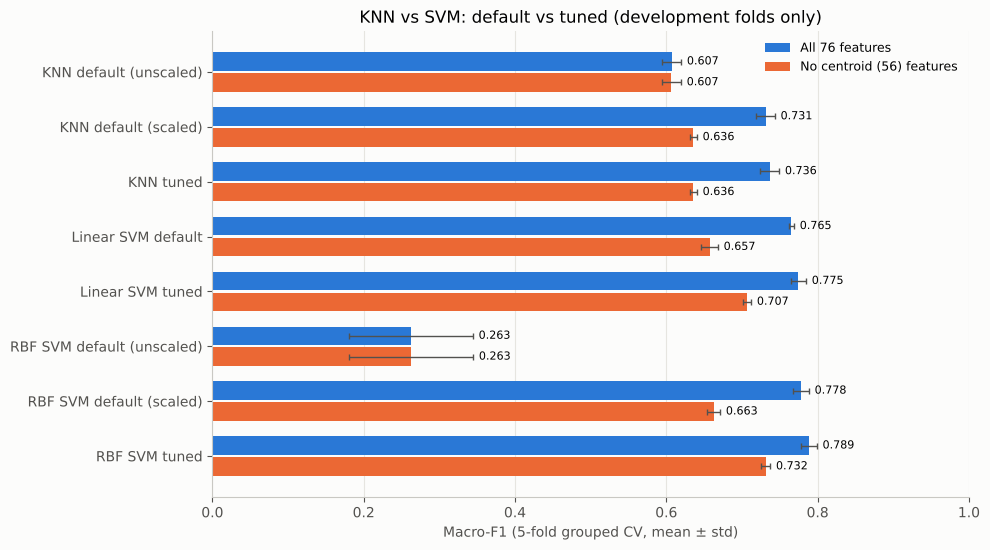

In [15]:
order = list(final.model.unique())[::-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, (fs, col) in enumerate([("All 76", BLUE), ("No centroid (56)", ORANGE)]):
    s = final[final.features == fs].set_index("model").loc[order]
    b = ax.barh(np.arange(len(order)) + (0.5 - i) * 0.38, s.macro_F1, 0.34, color=col, label=f"{fs} features",
                xerr=s.F1_std, error_kw=dict(ecolor="#52514e", lw=1, capsize=2))
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=4)
ax.set_yticks(range(len(order)), order); ax.set_xlim(0, 1); ax.set_xlabel("Macro-F1 (5-fold grouped CV, mean ± std)")
ax.xaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("KNN vs SVM: default vs tuned (development folds only)")
fig.tight_layout(); fig.savefig(FIGURES / "step6_final_comparison.png", dpi=200); plt.show()

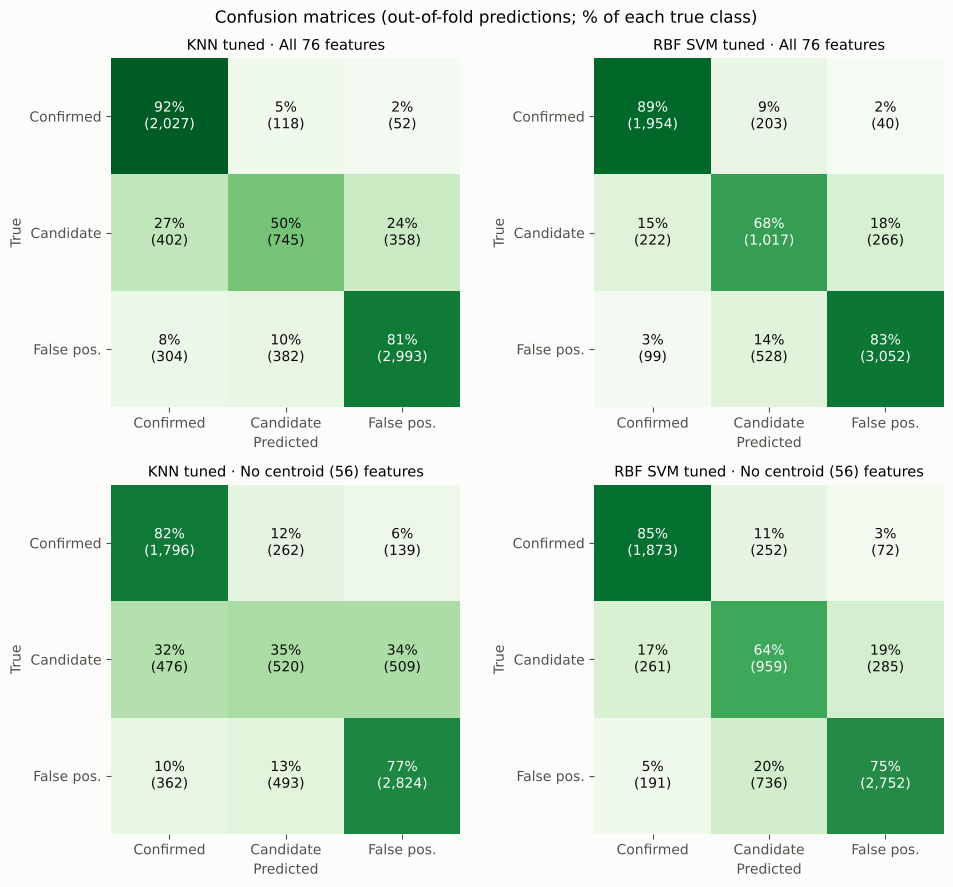

class                           CONFIRMED  CANDIDATE  FALSE POSITIVE
features         model                                              
All 76           KNN tuned          0.923      0.495           0.814
                 RBF SVM tuned      0.889      0.676           0.830
No centroid (56) KNN tuned          0.817      0.346           0.768
                 RBF SVM tuned      0.853      0.637           0.748

In [16]:
labels = ["Confirmed", "Candidate", "False pos."]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, key in zip(axes.ravel(), [(fs, m) for fs in FEATURE_SETS for m in ["KNN tuned", "RBF SVM tuned"]]):
    cm = cms[key]; pct = cm / cm.sum(1, keepdims=True)
    ax.imshow(pct, cmap="Greens", vmin=0, vmax=1)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{pct[r, c]:.0%}\n({cm[r, c]:,})", ha="center", va="center", fontsize=10,
                    color="white" if pct[r, c] > 0.55 else "#0b0b0b")
    ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{key[1]} · {key[0]} features", fontsize=10.5)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("Confusion matrices (out-of-fold predictions; % of each true class)")
fig.tight_layout(); fig.savefig(FIGURES / "step6_confusion_matrices.png", dpi=200); plt.show()

display(per_class[per_class.model.str.contains("tuned") & ~per_class.model.str.contains("Linear")]
        .pivot_table(index=["features", "model"], columns="class", values="recall", sort=False)[CLASSES].round(3))

**What I found:**
- **The tuned RBF SVM is my best model:** macro-F1 about 0.79 and ROC-AUC about 0.92 with all 76 features, and about 0.73 / 0.89 without the centroid columns.
- **SVM beats KNN** everywhere, and the gap is larger without the centroid columns.
- **Candidate is the hardest class.** The RBF SVM finds about 68% of Candidates compared with about 89% of Confirmed planets. KNN finds only about 35–50% of Candidates. This makes sense: Candidates are signals NASA hasn't resolved yet.
- **The most serious mistake is rare.** The RBF SVM labels a confirmed planet as a False Positive only about 2–3% of the time.
- **The centroid columns matter.** Removing them lowers every scaled model by about 0.06–0.12 macro-F1.

## Step 7: Finalizing the SVM
In Step 5 the best C without centroid columns (30) was at the edge of the grid, so I tried larger values. I also tested whether adjusting the decision threshold for each class could catch more Candidates.

### 7a. Larger C values

In [17]:
ext_grids = {"All 76": {"model__C": [10, 30, 100, 300], "model__gamma": ["scale", 0.003, 0.01]},
             "No centroid (56)": {"model__C": [10, 30, 100, 300], "model__gamma": [0.003, 0.01, 0.03]}}
out = []
for fs, grid in ext_grids.items():
    gs = GridSearchCV(make_pipe(SVC(class_weight="balanced")), grid, cv=CV, scoring="f1_macro",
                      n_jobs=-1, refit=False, return_train_score=True).fit(X[FEATURE_SETS[fs]], y)
    r = pd.DataFrame(gs.cv_results_)
    out.append(pd.DataFrame({"features": fs, "C": r.param_model__C, "gamma": r.param_model__gamma.astype(str),
        "macro_F1": r.mean_test_score, "F1_std": r.std_test_score, "train_macro_F1": r.mean_train_score}))
ext = pd.concat(out, ignore_index=True); ext.to_csv(RESULTS / "svm_extended_C.csv", index=False)
display(ext.loc[ext.groupby("features", sort=False)["macro_F1"].idxmax()].round(3))

,features,C,gamma,macro_F1,F1_std,train_macro_F1
7,All 76,100,0.003,0.790,0.010,0.864
18,No centroid (56),100,0.003,0.734,0.008,0.783


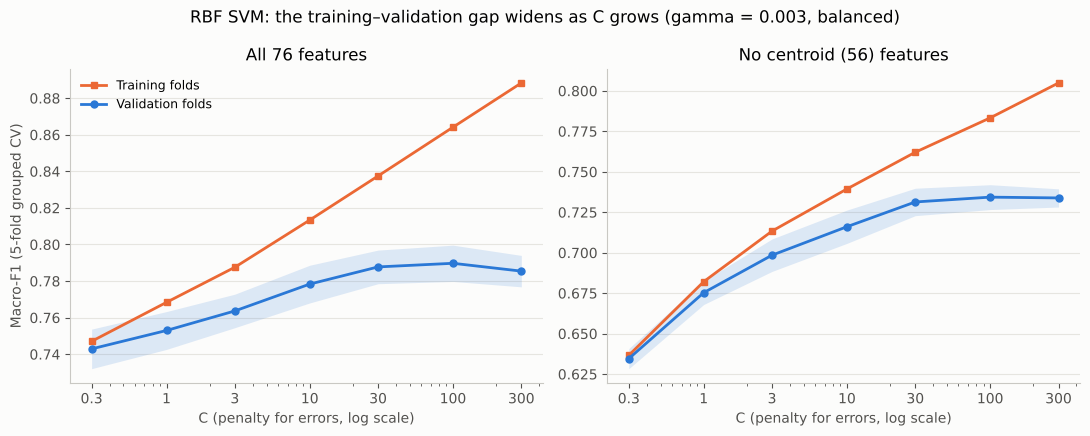

In [18]:
# Combine Step 5 and Step 7 results at gamma = 0.003 to see the full C curve
old = svm_grid_df[(svm_grid_df.kernel == "RBF") & (svm_grid_df.class_weight == "balanced")][["features", "C", "gamma", "macro_F1", "F1_std", "train_macro_F1"]]
c_curve = pd.concat([old, ext]).drop_duplicates(["features", "C", "gamma"], keep="last")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, fs in zip(axes, FEATURE_SETS):
    s = c_curve[(c_curve.features == fs) & (c_curve.gamma == "0.003")].sort_values("C")
    ax.plot(s.C, s.train_macro_F1, "-s", color=ORANGE, lw=2, ms=5, label="Training folds")
    ax.plot(s.C, s.macro_F1, "-o", color=BLUE, lw=2, ms=5, label="Validation folds")
    ax.fill_between(s.C, s.macro_F1 - s.F1_std, s.macro_F1 + s.F1_std, color=BLUE, alpha=0.15, lw=0)
    ax.set_xscale("log"); ax.set_xticks(s.C.tolist()); ax.set_xticklabels([f"{v:g}" for v in s.C])
    ax.set_xlabel("C (penalty for errors, log scale)"); ax.set_title(f"{fs} features"); tidy(ax)
axes[0].set_ylabel("Macro-F1 (5-fold grouped CV)"); axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("RBF SVM: the training–validation gap widens as C grows (gamma = 0.003, balanced)")
fig.tight_layout(); fig.savefig(FIGURES / "step7_svm_extended_C.png", dpi=200); plt.show()

Larger C values add at most +0.002 macro-F1, well within the normal variation between folds, so the score has plateaued. Beyond C = 100 the training score keeps rising while validation stays flat or drops, which is the start of overfitting.

### 7b. Per-class decision thresholds
I added an offset to the SVM's score for the Candidate and False Positive classes and searched for the offsets that maximize macro-F1. To keep the test honest, the offsets are chosen **only on the four training folds** (using their own inner cross-validation) and then applied to the held-out fold.

In [19]:
OFFSETS = np.round(np.arange(-1.0, 1.01, 0.05), 2)
final_rbf = {"All 76": dict(C=10, gamma="scale"), "No centroid (56)": dict(C=30, gamma=0.01)}

def fold_scores(pipe, cols, tr, va):
    m = clone(pipe).fit(X.loc[tr, cols], y[tr])
    s = m.decision_function(X.loc[va, cols])
    return s[:, [list(m.classes_).index(c) for c in CLASSES]]

def best_offsets(S, y_true):
    best = (-1, 0, 0)
    for a in OFFSETS:
        for b in OFFSETS:
            p = np.array(CLASSES)[(S + [0, a, b]).argmax(1)]
            f = f1_score(y_true, p, average="macro")
            if f > best[0]: best = (f, a, b)
    return best[1:]

rows = []
for fs, cols in FEATURE_SETS.items():
    pipe = make_pipe(SVC(class_weight="balanced", **final_rbf[fs]))
    base = np.empty(len(y), dtype=object); tuned = base.copy(); chosen = []
    for k in range(5):
        outer_tr = folds != k
        inner = [j for j in range(5) if j != k]
        S_in = np.vstack([fold_scores(pipe, cols, outer_tr & (folds != j), folds == j) for j in inner])
        idx = np.concatenate([np.where(folds == j)[0] for j in inner])
        a, b = best_offsets(S_in, y[idx]); chosen.append((a, b))
        S_out = fold_scores(pipe, cols, outer_tr, folds == k)
        base[folds == k] = np.array(CLASSES)[S_out.argmax(1)]
        tuned[folds == k] = np.array(CLASSES)[(S_out + [0, a, b]).argmax(1)]
    print(f"{fs}: offsets chosen per fold (Candidate, False Positive) = {chosen}")
    for name, pred in [("default thresholds", base), ("tuned class thresholds", tuned)]:
        _, rc, _, _ = precision_recall_fscore_support(y, pred, labels=CLASSES)
        rows.append({"features": fs, "RBF SVM with": name,
                     "macro_F1": np.mean([f1_score(y[folds == k], pred[folds == k], average="macro") for k in range(5)]),
                     "Candidate recall": rc[1], "Confirmed recall": rc[0], "False Positive recall": rc[2]})
thresholds = pd.DataFrame(rows); thresholds.to_csv(RESULTS / "threshold_tuning.csv", index=False)
display(thresholds.round(3))

All 76: offsets chosen per fold (Candidate, False Positive) = [(np.float64(-0.05), np.float64(-0.05)), (np.float64(0.95), np.float64(1.0)), (np.float64(0.9), np.float64(1.0)), (np.float64(1.0), np.float64(0.95)), (np.float64(1.0), np.float64(0.9))]


No centroid (56): offsets chosen per fold (Candidate, False Positive) = [(np.float64(0.25), np.float64(0.1)), (np.float64(-0.75), np.float64(0.2)), (np.float64(0.8), np.float64(1.0)), (np.float64(1.0), np.float64(0.85)), (np.float64(1.0), np.float64(0.9))]


,features,RBF SVM with,macro_F1,Candidate recall,Confirmed recall,False Positive recall
0,All 76,default thresholds,0.789,0.674,0.890,0.831
1,All 76,tuned class thresholds,0.789,0.680,0.882,0.831
2,No centroid (56),default thresholds,0.733,0.637,0.854,0.750
3,No centroid (56),tuned class thresholds,0.733,0.645,0.847,0.750


Threshold tuning doesn't change macro-F1 and adds less than one point of Candidate recall. The chosen offsets also jump around from fold to fold, so there's no stable pattern to learn. `class_weight="balanced"` from Step 5 already does this job.

**Final models (kept from Step 5, the simpler choice):**
- All 76 features: RBF SVM, C = 10, gamma = "scale", balanced
- No centroid (56): RBF SVM, C = 30, gamma = 0.01, balanced

## Step 10: Bias-variance analysis
For each model I compare the training score with the validation score as the model gets more complex:
- **Underfitting (high bias):** too simple, so both scores are low and close together.
- **Overfitting (high variance):** too complex, so training stays high while validation drops.
- **Sweet spot:** validation is highest.

KNN gets more complex as k gets **smaller**. The SVM gets more complex as C or gamma gets **larger**. C works as regularization: a smaller C means more regularization and a simpler model.

In [20]:
G = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
pipe = make_pipe(SVC(C=10, class_weight="balanced"))
tr, va = validation_curve(pipe, X[ALL_76], y, param_name="model__gamma", param_range=G,
                          cv=CV, scoring="f1_macro", n_jobs=-1)
gamma_curve = pd.DataFrame({"gamma": G, "train_macro_F1": tr.mean(1), "macro_F1": va.mean(1), "F1_std": va.std(1)})
gamma_curve.to_csv(RESULTS / "svm_gamma_curve.csv", index=False)
display(gamma_curve.round(3))

,gamma,train_macro_F1,macro_F1,F1_std
0,0.001,0.778,0.760,0.009
1,0.003,0.813,0.778,0.010
2,0.010,0.868,0.788,0.008
3,0.030,0.936,0.783,0.012
4,0.100,0.992,0.754,0.013
5,0.300,1.000,0.693,0.016
6,1.000,1.000,0.456,0.014


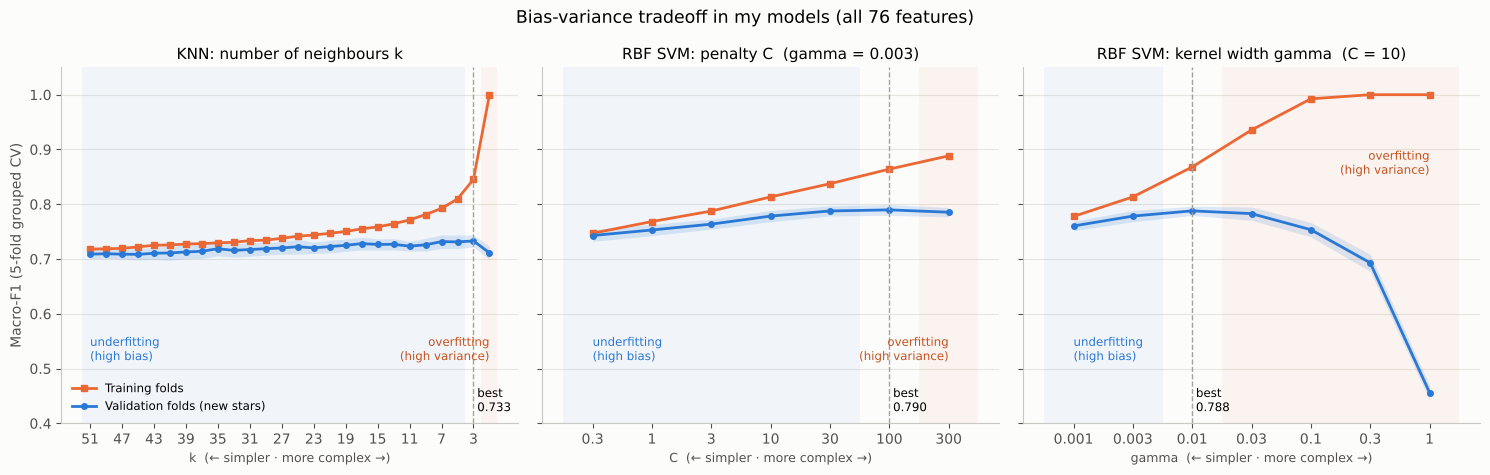

,model,regime,setting,train,validation,gap
0,KNN (k),Too simple,k = 51,0.718,0.709,0.009
1,KNN (k),Sweet spot,k = 3,0.845,0.733,0.112
2,KNN (k),Too complex,k = 1,1.000,0.711,0.289
3,RBF SVM (C),Too simple,C = 0.3,0.747,0.743,0.004
4,RBF SVM (C),Sweet spot,C = 100,0.864,0.790,0.074
5,RBF SVM (C),Too complex,C = 300,0.888,0.785,0.103
6,RBF SVM (gamma),Too simple,gamma = 0.001,0.778,0.760,0.017
7,RBF SVM (gamma),Sweet spot,gamma = 0.01,0.868,0.788,0.080
8,RBF SVM (gamma),Too complex,gamma = 1,1.000,0.456,0.544


In [21]:
k_df = ksweep[ksweep.features == "All 76"].sort_values("k", ascending=False)
c_df = c_curve[(c_curve.features == "All 76") & (c_curve.gamma == "0.003")].sort_values("C")
panels = [("KNN: number of neighbours k", k_df, "k"), ("RBF SVM: penalty C  (gamma = 0.003)", c_df, "C"),
          ("RBF SVM: kernel width gamma  (C = 10)", gamma_curve, "gamma")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
summary = []
for ax, (title, df, col) in zip(axes, panels):
    x = np.arange(len(df)); bi = int(np.argmax(df.macro_F1.values))
    ax.axvspan(-0.5, bi - 0.5, color=BLUE, alpha=0.05, lw=0); ax.axvspan(bi + 0.5, len(df) - 0.5, color=ORANGE, alpha=0.06, lw=0)
    ax.plot(x, df.train_macro_F1, "-s", color=ORANGE, lw=2, ms=4, label="Training folds")
    ax.plot(x, df.macro_F1, "-o", color=BLUE, lw=2, ms=4, label="Validation folds (new stars)")
    ax.fill_between(x, df.macro_F1 - df.F1_std, df.macro_F1 + df.F1_std, color=BLUE, alpha=0.15, lw=0)
    ax.axvline(bi, color=GRAY, ls="--", lw=1)
    ax.text(bi, 0.415, f" best\n {df.macro_F1.values[bi]:.3f}", fontsize=8.5, va="bottom")
    ax.text(0, 0.56, "underfitting\n(high bias)", fontsize=8.5, color=BLUE, va="top")
    ax.text(len(df) - 1, 0.90 if col == "gamma" else 0.56, "overfitting\n(high variance)", fontsize=8.5,
            color="#c4521f", va="top", ha="right")
    step = max(1, len(df) // 9); labels = [f"{v:g}" for v in df[col]]
    ax.set_xticks(x[::step]); ax.set_xticklabels(labels[::step])
    ax.set_title(title, fontsize=11); ax.set_xlabel(f"{col}  (← simpler · more complex →)", fontsize=9)
    ax.set_ylim(0.4, 1.05); tidy(ax)
    for regime, i in [("Too simple", 0), ("Sweet spot", bi), ("Too complex", len(df) - 1)]:
        r = df.iloc[i]
        summary.append({"model": title.split(":")[0] + f" ({col})", "regime": regime, "setting": f"{col} = {r[col]:g}",
                        "train": round(r.train_macro_F1, 3), "validation": round(r.macro_F1, 3),
                        "gap": round(r.train_macro_F1 - r.macro_F1, 3)})
axes[0].set_ylabel("Macro-F1 (5-fold grouped CV)"); axes[0].legend(frameon=False, fontsize=8.5, loc="lower left")
fig.suptitle("Bias-variance tradeoff in my models (all 76 features)", fontsize=12.5)
fig.tight_layout(); fig.savefig(FIGURES / "step10_bias_variance.png", dpi=200); plt.show()
bv = pd.DataFrame(summary); bv.to_csv(RESULTS / "bias_variance_summary.csv", index=False); display(bv)

**What I found:**
- All three settings show the classic bias-variance pattern.
- **gamma is the most dangerous setting.** At gamma = 1, the SVM scores a perfect 1.00 on training but only about 0.46 on new stars. Each point's influence becomes so local that the model memorizes the training data.
- **k = 1 memorizes too:** perfect on training, but no better than k = 51 on new stars.
- **C overfits slowly.** The training–validation gap grows gradually, so it's easy to miss without plotting both lines.
- This explains why tuning mattered more for SVM than for KNN: SVM has two settings that can push it into overfitting, while KNN's curve is fairly flat.

## Summary
| | All 76 features | No centroid (56) |
|---|---|---|
| Best KNN (tuned) | macro-F1 ≈ 0.74, ROC-AUC ≈ 0.90 | macro-F1 ≈ 0.64, ROC-AUC ≈ 0.83 |
| Best Linear SVM (tuned) | macro-F1 ≈ 0.78, ROC-AUC ≈ 0.91 | macro-F1 ≈ 0.71, ROC-AUC ≈ 0.88 |
| **Best RBF SVM (tuned)** | **macro-F1 ≈ 0.79, ROC-AUC ≈ 0.92** | **macro-F1 ≈ 0.73, ROC-AUC ≈ 0.89** |

**Key takeaways**
1. Feature scaling is the single most important step for KNN and SVM.
2. The RBF SVM with class balancing is my strongest model.
3. Candidate is the hardest class, because its labels are the least certain.
4. The centroid columns carry a strong vetting signal, so results are reported with and without them.
5. The bias-variance curves show clear sweet spots, and gamma overfits fastest.

**Next (with the team):** agree on the main feature set (Step 8), open the test set once (Step 9), and compare all six models (Step 11).

*All results here use the development folds only. The test set has not been opened.*